## Plot 2D slices of the gamma ray, synchrotron, and number densities

In [9]:
import numpy as np
import matplotlib.pyplot as plt
import os
import astropy.units as u
import json

import matplotlib.colors as mcolors
import matplotlib.cm as cm
from mpl_toolkits.axes_grid1 import make_axes_locatable

from transform_data import get_transformed_data

import flash_amr_tools
import h5py

In [10]:
fig_dir = "/home/kwatanabe/Projects/cr-bowshocks/figures/emission"
flash_output_dir = "/home/kwatanabe/Projects/cr-bowshocks/outputs_new"
data_dir = "/home/kwatanabe/Projects/cr-bowshocks/crbowshock_analysis_tools/data"

# load the bowshock config
bowshock_config = json.load(open("../../config/bowshock_config.json", "r"))["config"]

In [11]:
sims = ["ISM-v30", "ISM-v30-MDiff", "ISM-v30-HDiff", "ISM-v100"]
fields = ["ncre", "gamma", "synch"]

sim_textlabel = {
    "ISM-v30" : (13, -22),
    "ISM-v30-MDiff" : (13, -22),
    "ISM-v30-HDiff" : (13, -22),
    "ISM-v100" : (13, -22)
}

field_labels = {
    "ncr" : r"$n_\mathrm{CR, p}$ / cm$^{-3}$",
    "gamma" : r"$j_\gamma$ / erg s$^{-1}$ cm$^{-3}$",
    "ncre" : r"$\epsilon_\mathrm{CR, e}$ / erg cm$^{-3}$",
    "synch" : r"$j_\mathrm{syn, 1.4GHz}$ / erg s$^{-1}$ cm$^{-3}$"
}

field_cmaps = {
    "ncr" : cm.BuGn_r,
    "ncre" : cm.RdPu_r,
    "gamma" : cm.plasma,
    "synch" : cm.cividis
}

field_lims = {
    "ncr" : [1e-15, 1e-7],
    "ncre" : [1e-18, 1e-12],
    "gamma" : [1e-36, 1e-26],
    "synch" : [1e-40, 1e-30]
}

<KeysViewHDF5 ['t100kyr', 't100kyr_bbox', 't150kyr', 't150kyr_bbox', 't200kyr', 't200kyr_bbox', 't50kyr', 't50kyr_bbox']>
2.6705756990408462e-17 3.703262647274495e-12
<KeysViewHDF5 ['t00kyr', 't0_bbox', 't100kyr', 't10_bbox', 't150kyr', 't15_bbox', 't200kyr', 't20_bbox', 't50kyr', 't5_bbox']>
3.135092563662569e-36 4.917600271259537e-28
<KeysViewHDF5 ['t00kyr', 't0_bbox', 't100kyr', 't10_bbox', 't150kyr', 't15_bbox', 't200kyr', 't20_bbox', 't50kyr', 't5_bbox']>
0.0 3.310257537522952e-30
<KeysViewHDF5 ['t100kyr', 't100kyr_bbox', 't150kyr', 't150kyr_bbox', 't200kyr', 't200kyr_bbox', 't50kyr', 't50kyr_bbox']>
2.6626675135074624e-17 4.326596234180292e-13
<KeysViewHDF5 ['t00kyr', 't0_bbox', 't100kyr', 't10_bbox', 't150kyr', 't15_bbox', 't200kyr', 't20_bbox', 't50kyr', 't5_bbox']>
3.55572298216557e-36 1.2921025964779154e-27
<KeysViewHDF5 ['t00kyr', 't0_bbox', 't100kyr', 't10_bbox', 't150kyr', 't15_bbox', 't200kyr', 't20_bbox', 't50kyr', 't5_bbox']>
0.0 2.4566242314701934e-30
<KeysViewHDF5 ['t

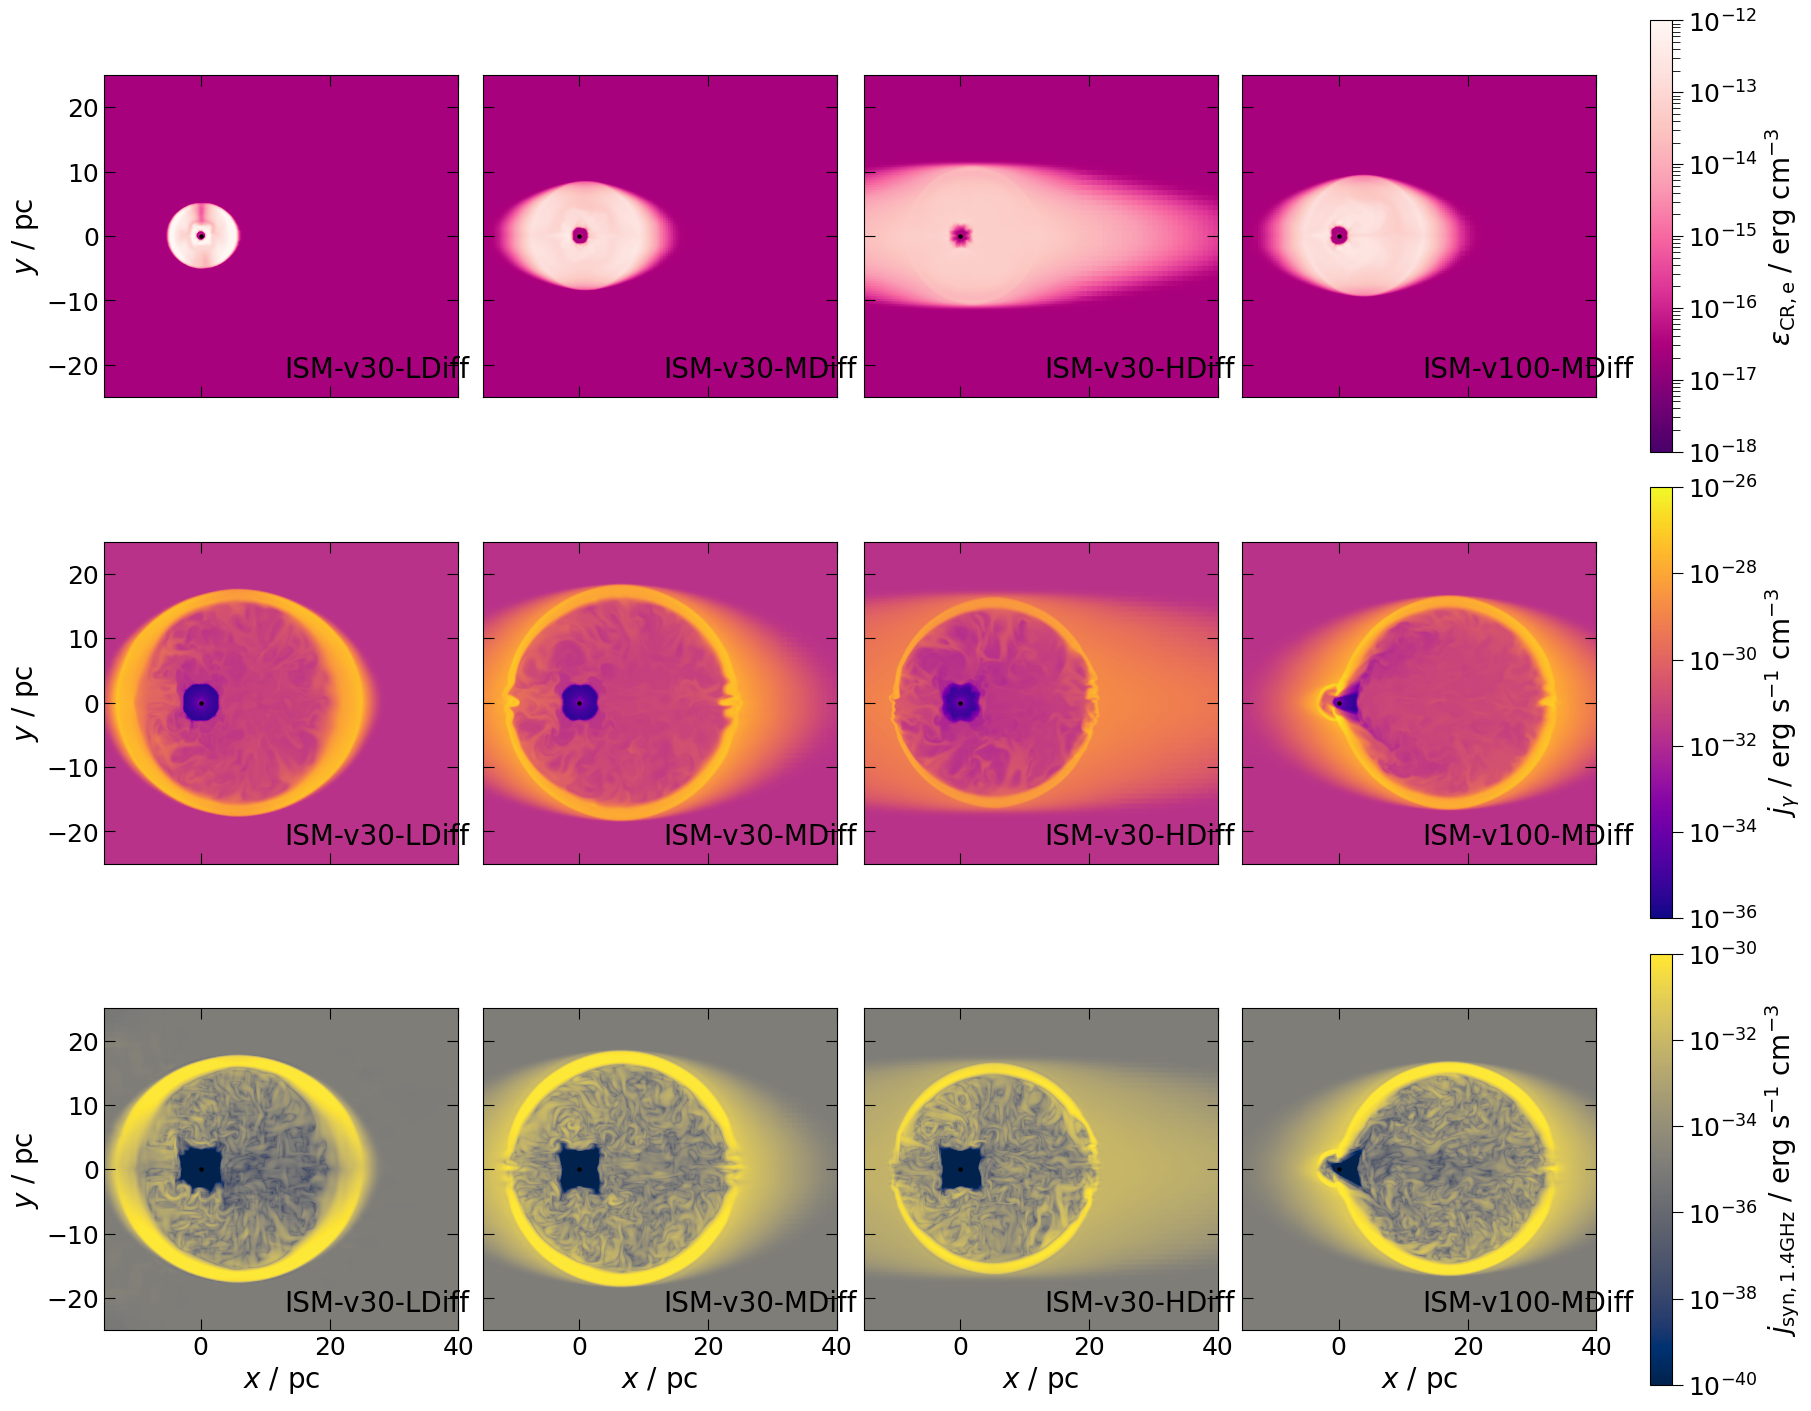

In [14]:
fig = plt.figure(figsize=(18, 14), constrained_layout=True)
gs = fig.add_gridspec(len(fields), len(sims), hspace=0, wspace=0)
axs = gs.subplots(sharex=True, sharey=True)

for isim, sim in enumerate(sims):

    for ifield, field in enumerate(fields):

        f_label = "ncr" if field.find("ncre") != -1 else field

        # write data to h5py file
        with h5py.File(f"{data_dir}/emission_data_{f_label}.h5", "r") as pf:
            if field == "ncr":
                
                field_slice = pf[f"{sim}/proton/slices/t200kyr"][()]
                bbox =  pf[f"{sim}/proton/slices/t20kyr_bbox"][()]
            elif field == "ncre":
                print(pf[f"{sim}/electron/slices"].keys())
                field_slice = pf[f"{sim}/electron/slices/t200kyr"][()]
                bbox =  pf[f"{sim}/electron/slices/t200kyr_bbox"][()]
            else:
                print(pf[f"{sim}/slices"].keys())
                field_slice = pf[f"{sim}/slices/t200kyr"][()]
                bbox =  pf[f"{sim}/slices/t20_bbox"][()]
        
        print(field_slice.min(), field_slice.max())

        low_cor, up_cor = bbox[0,:,0], bbox[-1,:,1]
        # extent for imshow
        extent = ([low_cor[0], up_cor[0], low_cor[1], up_cor[1]] * u.cm).to_value(u.pc)

        # normaliztion for color
        norm = mcolors.LogNorm(vmin=field_lims[field][0], vmax=field_lims[field][1], clip=True)

        im = axs[ifield, isim].imshow(field_slice.T, norm=norm, cmap=field_cmaps[field], origin="lower", extent=extent)
        axs[ifield, isim].scatter(0, 0, s=5.0, color="k")

        axs[ifield, isim].set_xlim(-15,40)
        axs[ifield, isim].set_ylim(-25,25)

        # labels
        if ifield == len(fields) -1:
            axs[ifield, isim].set_xlabel("$x$ / pc", fontsize=20)
        # if isim == 0:
        if isim == 0 :
            axs[ifield, isim].set_ylabel("$y$ / pc", fontsize=20)
        # ticks
        axs[ifield, isim].tick_params(axis='both', direction="in", which='major', size=8, labelsize=18, top=True, right=True)
        axs[ifield, isim].tick_params(axis='both', direction="in", which='minor', size=6, labelsize=16, top=True, right=True)

        if isim == len(sims) -1:
        # colorbar
        # make separate axes for each image
        # divider = make_axes_locatable(axs[isim,ifield])
        # cax = divider.append_axes("bottom", size="5%", pad=1.0)
            sm = cm.ScalarMappable(cmap=field_cmaps[field], norm=norm)

            cb = fig.colorbar(sm, ax=axs[ifield,isim], orientation="vertical")
            cb.ax.set_ylabel(field_labels[field], fontsize=20)
            cb.ax.tick_params(axis='both', which='major', size=8, labelsize=18)
            cb.ax.tick_params(axis='both', which='minor', size=6, labelsize=18)

            # scales
            cb.ax.set_yscale("log")
            # cb.ax.tick_params(rotation=90)

        # add annotations for the simulation labels
        axs[ifield,isim].annotate(bowshock_config[sim]["label"], xy=sim_textlabel[sim], color="k", fontsize=20)

    pf.close()

# fig.savefig(f"{fig_dir}/2d_slices_t150.png", dpi=200, bbox_inches="tight")